<a href="https://colab.research.google.com/github/abdalla-sharkawi/redicts-How-students-learn-best/blob/main/Predicts_How_students_learn_best.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [77]:
!pip install -q pandas numpy scikit-learn matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [78]:
METHODS = ["practice_tests", "flashcards", "group_study", "reading_notes", "video_lectures"]
NUM = ["study_hours", "sleep_hours", "attendance", "prev_gpa", "distraction"]

rng = np.random.default_rng(42)
N = 3000

df = pd.DataFrame({
    "study_hours": rng.uniform(2, 30, N),      # hours per week
    "sleep_hours": rng.uniform(4, 10, N),      # hours per night
    "attendance": rng.uniform(50, 100, N),     # percent
    "prev_gpa": rng.uniform(1.5, 4.0, N),      # previous GPA
    "distraction": rng.uniform(0, 10, N),      # self-rated 0-10
    "method": rng.choice(METHODS, N),
})

# Hidden "truth" used to generate marks (the model will try to learn this)
method_effect = df["method"].map({
    "practice_tests": 6, "flashcards": 4, "group_study": 1,
    "reading_notes": 0, "video_lectures": -1,
}).astype(float)
# Group study helps students who get distracted easily
method_effect += np.where(df["method"] == "group_study", 0.4 * df["distraction"] - 2, 0)

marks = (
    25
    + 0.8 * df["study_hours"]
    + 0.15 * df["attendance"]
    + 8 * df["prev_gpa"]
    - 0.9 * df["distraction"]
    - 0.5 * np.abs(df["sleep_hours"] - 8)
    + method_effect
    + rng.normal(0, 4, N)            # random noise
)
df["marks"] = np.clip(marks, 0, 100).round(1)

df.head()

,study_hours,sleep_hours,attendance,prev_gpa,distraction,method,marks
0,23.670769,8.975327,72.773819,3.684147,5.180657,flashcards,89.6
1,14.288596,7.564576,55.942899,2.115142,3.536339,flashcards,64.3
2,26.040742,5.469128,78.458671,2.722410,0.750558,video_lectures,76.0
3,21.526305,8.474050,57.821441,1.574293,9.909720,practice_tests,69.4
4,4.636966,4.506885,53.047917,1.522200,1.747737,practice_tests,56.2


In [79]:
print(df.describe().round(2))
print("\nAverage marks by method:")
print(df.groupby("method")["marks"].mean().sort_values(ascending=False).round(2))

df[NUM + ["marks"]].corr()["marks"].sort_values(ascending=False)

       study_hours  sleep_hours  attendance  prev_gpa  distraction    marks
count      3000.00      3000.00     3000.00   3000.00      3000.00  3000.00
mean         15.99         6.94       75.07      2.75         5.02    67.85
std           8.12         1.72       14.39      0.72         2.86    10.37
min           2.01         4.00       50.02      1.50         0.00    33.30
25%           8.85         5.46       62.75      2.11         2.54    60.50
50%          15.89         6.92       75.26      2.77         5.06    67.90
75%          23.17         8.41       87.21      3.36         7.47    75.20
max          29.99        10.00      100.00      4.00        10.00    98.10

Average marks by method:
method
practice_tests    71.69
flashcards        69.82
group_study       66.75
reading_notes     66.36
video_lectures    64.76
Name: marks, dtype: float64


,marks
marks,1.000000
study_hours,0.613364
prev_gpa,0.563171
attendance,0.182383
sleep_hours,0.043640
distraction,-0.219177


In [80]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

scaler = StandardScaler().fit(train_df[NUM])   # fit only on training data

def preprocess(d):
    numeric = scaler.transform(d[NUM])
    onehot = (pd.get_dummies(d["method"])
                .reindex(columns=METHODS, fill_value=0)
                .values.astype(float))
    return np.hstack([numeric, onehot]).astype("float32")

X_train = preprocess(train_df)
X_test = preprocess(test_df)
y_train = train_df["marks"].values.astype("float32")
y_test = test_df["marks"].values.astype("float32")

print("X_train:", X_train.shape, " X_test:", X_test.shape)

X_train: (2400, 10)  X_test: (600, 10)


In [81]:
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1)                       # predicted marks
])

model.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])

early = keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early],
    verbose=0,
)

print("Epochs trained:", len(history.history["loss"]))
model.summary()

Epochs trained: 74


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,453 (33.02 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,636 (22.02 KB)

Test MAE: 3.32 marks
Test R²:  0.835


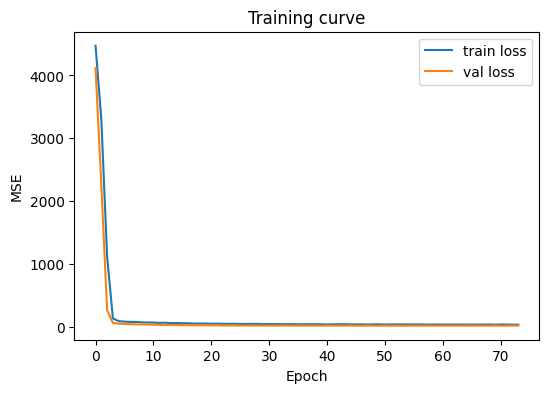

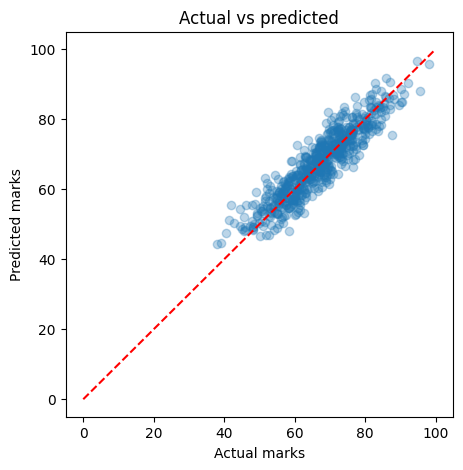

In [82]:
y_pred = model.predict(X_test, verbose=0).flatten()

print(f"Test MAE: {mean_absolute_error(y_test, y_pred):.2f} marks")
print(f"Test R²:  {r2_score(y_test, y_pred):.3f}")

plt.figure(figsize=(6, 4))
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.legend(); plt.title("Training curve")
plt.show()

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual marks"); plt.ylabel("Predicted marks"); plt.title("Actual vs predicted")
plt.show()

In [83]:
def recommend_method(student: dict):
    results = []
    for m in METHODS:
        row = pd.DataFrame([{**student, "method": m}])
        predicted = float(model.predict(preprocess(row), verbose=0)[0][0])
        results.append((m, round(predicted, 1)))
    results.sort(key=lambda x: x[1], reverse=True)

    best_method, best_marks = results[0]
    print(f"Predicted best study method: {best_method.replace('_', ' ').title()}")
    print(f"Predicted marks with it: {best_marks}\n")
    print("All methods ranked:")
    for m, mk in results:
        print(f"  {m:<16} {mk}")
    return results

# Example student
student = {
    "study_hours": 10,
    "sleep_hours": 6.5,
    "attendance": 78,
    "prev_gpa": 2.8,
    "distraction": 7,
}
_ = recommend_method(student)

Predicted best study method: Practice Tests
Predicted marks with it: 66.0

All methods ranked:
  practice_tests   66.0
  flashcards       64.0
  group_study      60.8
  reading_notes    60.2
  video_lectures   59.1


In [84]:
def predict_marks(student: dict, method: str) -> float:
    row = pd.DataFrame([{**student, "method": method}])
    return round(float(model.predict(preprocess(row), verbose=0)[0][0]), 1)

print("Predicted marks for the example student with practice tests:",
      predict_marks(student, "practice_tests"))

Predicted marks for the example student with practice tests: 66.0


In [88]:
import joblib
import pandas as pd

NUM = ["study_hours", "sleep_hours", "attendance", "prev_gpa", "distraction"]

scaler = joblib.load("scaler.pkl")

readable = pd.DataFrame({
    "feature": NUM,
    "mean": scaler.mean_.round(3),
    "std_dev": scaler.scale_.round(3),
})
print(readable)
readable.to_csv("scaler_values.csv", index=False)
files.download("scaler_values.csv")

       feature    mean  std_dev
0  study_hours  16.067    8.140
1  sleep_hours   6.934    1.710
2   attendance  75.185   14.388
3     prev_gpa   2.746    0.719
4  distraction   4.992    2.852


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [86]:
my_student = {
    "study_hours": 7,      # hours per week
    "sleep_hours": 2,       # hours per night
    "attendance": 60,       # percent
    "prev_gpa": 3.2,
    "distraction": 4,       # 0 to 10
}
recommend_method(my_student)

Predicted best study method: Practice Tests
Predicted marks with it: 65.9

All methods ranked:
  practice_tests   65.9
  flashcards       64.1
  group_study      61.3
  reading_notes    60.8
  video_lectures   59.8


[('practice_tests', 65.9),
 ('flashcards', 64.1),
 ('group_study', 61.3),
 ('reading_notes', 60.8),
 ('video_lectures', 59.8)]

In [87]:
import joblib
from tensorflow import keras
import pandas as pd
import numpy as np

model = keras.models.load_model("study_predictor.keras")
scaler = joblib.load("scaler.pkl")

NUM = ["study_hours", "sleep_hours", "attendance", "prev_gpa", "distraction"]
METHODS = ["practice_tests", "flashcards", "group_study", "reading_notes", "video_lectures"]

def preprocess(d):
    numeric = scaler.transform(d[NUM])
    onehot = (pd.get_dummies(d["method"])
                .reindex(columns=METHODS, fill_value=0)
                .values.astype(float))
    return np.hstack([numeric, onehot]).astype("float32")

def predict_marks(student, method):
    row = pd.DataFrame([{**student, "method": method}])
    return round(float(model.predict(preprocess(row), verbose=0)[0][0]), 1)

print(predict_marks(my_student, "practice_tests"))

65.9
